# SilPart-Aware Compositional Decipherment (glyph → phoneme)

## From syllabic substitution to compositional encoding

The SilPart model (d = 0.445, the closest to the Voynich among 11 candidates) proposes that each syllable is **built compositionally** from glyphs with positional roles. This implies that the encoding unit is not the whole syllable but the **individual glyph**.

The syllabic Bayesian notebook produces a robust ranking (Hebrew #1, Arabic #2) but with low posterior confidence (49.5%), due to the enormous search space (800! permutations in bijective syllable→syllable mapping).

### Key difference

| Aspect | Syllabic (existing) | Compositional (this notebook) |
|--------|---------------------|-------------------------------|
| Mapping unit | syllable → syllable | glyph → character |
| Source inventory | ~792 functional syllables | ~166 glyphs |
| Target inventory | ~200-800 syllables | ~27-36 characters |
| Mapping type | Bijective (1-to-1) | Many-to-one (several glyphs → same char) |
| Search space | 800! permutations | 166 × 30 assignments |
| Evaluation LM | Syllabic bigram | Character trigram |

**Hypothesis**: If glyphs encode individual phonological components, a glyph→character mapping under a character LM should: (1) confirm the syllabic ranking, (2) improve mapping confidence due to the smaller search space, and (3) produce more readable consonantal reconstructions.

In [11]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import re, math, random, io, os, tarfile, json, warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import requests
from scipy import stats as sp_stats
from scipy.spatial.distance import jensenshannon, cosine
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import pairwise_distances
from sklearn.decomposition import PCA
from tqdm.notebook import tqdm

warnings.filterwarnings('ignore')

# ── Colours ──
COLOR_ONSET   = '#1565C0'
COLOR_NUCLEAR = '#2E7D32'
COLOR_CODA    = '#F57F17'
COLOR_FREE    = '#757575'

CLASE_COLORS = {
    'onset': COLOR_ONSET, 'nuclear': COLOR_NUCLEAR,
    'coda': COLOR_CODA, 'free': COLOR_FREE,
}

LANG_COLORS = {
    'Voynich': '#E53935', 'Turkish': '#6D4C41', 'Finnish': '#D81B60',
    'Latin': '#4CAF50', 'Hebrew': '#2196F3', 'Arabic': '#FF9800',
    'Aramaic': '#9C27B0',
}

ROLE_COLORS = {'C': '#1565C0', 'V': '#E53935', '?': '#9E9E9E'}

plt.rcParams.update({
    'figure.dpi': 130, 'savefig.dpi': 180,
    'font.size': 10, 'axes.titlesize': 11,
    'figure.facecolor': 'white',
})

print('Imports OK')

Imports OK


In [12]:
# ── Cell 2: Reused functions from the Bayesian notebook ──────────

def parsear_sta_completo(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens


def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras


def construir_matriz_transicion_intrapalabra(palabras):
    all_glyphs = sorted({g for p in palabras for g in p})
    index = {g: i for i, g in enumerate(all_glyphs)}
    n = len(all_glyphs)
    M_raw = np.zeros((n, n))
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            r, c = index[palabra[i]], index[palabra[i + 1]]
            M_raw[r, c] += 1
    row_sums = M_raw.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M_prob = M_raw / row_sums
    return M_raw, M_prob, all_glyphs, index


def segmentar_silabas_tp(palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20):
    all_trans_probs = []
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            if g1 in index_tr and g2 in index_tr:
                all_trans_probs.append(M_prob[index_tr[g1], index_tr[g2]])
    threshold_val = np.percentile(all_trans_probs, threshold_percentile)
    silabas_por_palabra = []
    for palabra in palabras:
        if len(palabra) == 0:
            continue
        syl = [palabra[0]]
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            p = M_prob[index_tr[g1], index_tr[g2]] if (g1 in index_tr and g2 in index_tr) else 0.0
            if p < threshold_val:
                silabas_por_palabra.append(tuple(syl))
                syl = [g2]
            else:
                syl.append(g2)
        if syl:
            silabas_por_palabra.append(tuple(syl))
        silabas_por_palabra.append(None)
    return silabas_por_palabra, all_trans_probs, threshold_val


def catalogar_silabas(silabas_por_palabra):
    syl_freq = Counter()
    syl_per_word = []
    syl_lengths = Counter()
    count_in_word = 0
    for item in silabas_por_palabra:
        if item is None:
            if count_in_word > 0:
                syl_per_word.append(count_in_word)
            count_in_word = 0
        else:
            syl_freq[item] += 1
            syl_lengths[len(item)] += 1
            count_in_word += 1
    if count_in_word > 0:
        syl_per_word.append(count_in_word)
    return syl_freq, syl_per_word, syl_lengths


def clasificar_silabas_posicionalmente(silabas_por_palabra, min_freq=5):
    words_as_syls = []
    current = []
    for item in silabas_por_palabra:
        if item is None:
            if current:
                words_as_syls.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words_as_syls.append(current)
    pos_counts = defaultdict(lambda: {'inicio': 0, 'medio': 0, 'final': 0, 'total': 0})
    for word_syls in words_as_syls:
        n = len(word_syls)
        for i, syl in enumerate(word_syls):
            pos_counts[syl]['total'] += 1
            if n == 1:
                pos_counts[syl]['inicio'] += 1
                pos_counts[syl]['final'] += 1
            elif i == 0:
                pos_counts[syl]['inicio'] += 1
            elif i == n - 1:
                pos_counts[syl]['final'] += 1
            else:
                pos_counts[syl]['medio'] += 1
    clase_silaba = {}
    stats = {}
    for syl, counts in pos_counts.items():
        if counts['total'] < min_freq:
            continue
        total = counts['total']
        r_ini = counts['inicio'] / total
        r_fin = counts['final'] / total
        r_med = counts['medio'] / total
        if r_ini >= 0.60 and r_fin < 0.30:
            clase = 'onset'
        elif r_fin >= 0.60 and r_ini < 0.30:
            clase = 'coda'
        elif r_med >= 0.40:
            clase = 'nuclear'
        else:
            clase = 'free'
        clase_silaba[syl] = clase
        stats[syl] = {'clase': clase, 'inicio': r_ini, 'medio': r_med,
                       'final': r_fin, 'total': total}
    return clase_silaba, stats


def syls_to_words(syls_flat):
    words, current = [], []
    for item in syls_flat:
        if item is None:
            if current:
                words.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words.append(current)
    return words


# ── Download functions ──

def descargar_turco():
    url = ('https://downloads.wortschatz-leipzig.de/corpora/'
           'tur_wikipedia_2021_100K.tar.gz')
    print('  Downloading Turkish corpus (Leipzig)...')
    resp = requests.get(url, timeout=120)
    resp.raise_for_status()
    todas_palabras = []
    with tarfile.open(fileobj=io.BytesIO(resp.content), mode='r:gz') as tar:
        for member in tar.getmembers():
            if member.name.endswith('-sentences.txt'):
                f = tar.extractfile(member)
                if f is None: continue
                texto = f.read().decode('utf-8')
                for linea in texto.splitlines():
                    partes = linea.split('\t', 1)
                    if len(partes) < 2: continue
                    oracion = partes[1].lower()
                    pals = re.findall(r'[a-z\u00e7\u015f\u011f\u0131\u00f6\u00fc]+', oracion)
                    for p in pals:
                        chars = list(p)
                        if 2 <= len(chars) <= 15:
                            todas_palabras.append(chars)
    print(f'  Turkish total: {len(todas_palabras):,} words')
    return todas_palabras


def descargar_fines():
    url = 'https://www.gutenberg.org/cache/epub/7000/pg7000.txt'
    print('  Downloading Kalevala...')
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()
    todas_palabras = []
    texto = resp.text.lower()
    pals = re.findall(r'[a-z\u00e4\u00f6]+', texto)
    for p in pals:
        chars = list(p)
        if 2 <= len(chars) <= 15:
            todas_palabras.append(chars)
    print(f'  Finnish total: {len(todas_palabras):,} words')
    return todas_palabras


def descargar_hebreo():
    libros = ['Genesis', 'Exodus', 'Leviticus', 'Numbers', 'Deuteronomy']
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/json/Tanakh/Torah/{}/Hebrew/Tanach%20with%20Text%20Only.json')
    todas_palabras = []
    for libro in libros:
        url = base_url.format(libro)
        print(f'  Downloading {libro}...')
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        for capitulo in data['text']:
            for versiculo in capitulo:
                texto = re.sub(r'[\u0591-\u05C7]', '', versiculo)
                pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                for p in pals:
                    chars = list(p)
                    if 2 <= len(chars) <= 15:
                        todas_palabras.append(chars)
    print(f'  Hebrew total: {len(todas_palabras):,} words')
    return todas_palabras


def descargar_arabe():
    urls = [
        ('https://raw.githubusercontent.com/amrayn/quran-text/main/'
         'quran-flat-no-tashkeel.txt', 'flat'),
        ('https://raw.githubusercontent.com/minijoomla/Tanzil/master/'
         'Packages/com_tanzil/site/resources/quran/quran-simple-plain.txt', 'plain'),
    ]
    texto = None
    for url, fmt in urls:
        print(f'  Trying {url.split("/")[-1]}...')
        try:
            resp = requests.get(url, timeout=30)
            resp.raise_for_status()
            texto = resp.text
            print(f'  OK ({len(texto):,} chars)')
            break
        except Exception as e:
            print(f'  Failed: {e}')
    if texto is None:
        raise RuntimeError('Could not download the Quran')
    todas_palabras = []
    for linea in texto.splitlines():
        linea = linea.strip()
        if not linea or linea.startswith('#'):
            continue
        partes = linea.split('|')
        contenido = partes[2] if len(partes) >= 3 else linea
        contenido = re.sub(r'[\u064B-\u065F\u0670]', '', contenido)
        pals = re.findall(r'[\u0621-\u064A]+', contenido)
        for p in pals:
            chars = list(p)
            if 2 <= len(chars) <= 15:
                todas_palabras.append(chars)
    print(f'  Arabic total: {len(todas_palabras):,} words')
    return todas_palabras


def descargar_vulgata():
    url = 'https://www.gutenberg.org/cache/epub/8300/pg8300.txt'
    print('  Downloading Vulgate...')
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()
    todas_palabras = []
    pals_raw = re.findall(r'[a-zA-Z]+', resp.text.lower())
    for p in pals_raw:
        chars = list(p)
        if 2 <= len(chars) <= 15:
            todas_palabras.append(chars)
    print(f'  Latin total: {len(todas_palabras):,} words')
    return todas_palabras


def descargar_arameo():
    """Targum Onkelos (biblical Aramaic) — exact parallel to the Hebrew Torah."""
    libros = [
        ('Genesis',      'Onkelos%20Genesis'),
        ('Exodus',       'Onkelos%20Exodus'),
        ('Leviticus',    'Onkelos%20Leviticus'),
        ('Numbers',      'Onkelos%20Numbers'),
        ('Deuteronomy',  'Onkelos%20Deuteronomy'),
    ]
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/cltk-flat/Tanakh/Targum/Onkelos/Torah/{}/Hebrew/merged.json')
    todas_palabras = []
    for nombre, path in libros:
        url = base_url.format(path)
        print(f'  Downloading Onkelos {nombre}...')
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        for versiculo in data.get('text', {}).values():
            texto = re.sub(r'<[^>]*>', '', str(versiculo))
            texto = re.sub(r'[֑-ׇ]', '', texto)
            pals = re.findall(r'[א-ת]+', texto)
            for p in pals:
                chars = list(p)
                if 2 <= len(chars) <= 15:
                    todas_palabras.append(chars)
    print(f'  Aramaic total: {len(todas_palabras):,} words')
    return todas_palabras


print('Reused functions loaded OK')

Funciones reutilizadas cargadas OK


In [13]:
# ── Cell 3: Load Voynich + glyph statistics ─────────────────
STA_PATH = 'corpus/voynich_sta.txt'

tokens_voynich = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens_voynich)
corpus_plano = [g for p in palabras for g in p]
VOCAB = sorted(set(corpus_plano))
N_VOYNICH = len(palabras)
print(f'Voynich: {N_VOYNICH:,} words, {len(corpus_plano):,} tokens, {len(VOCAB)} glyphs')

# Canonical TP-P20 segmentation (needed to classify glyphs)
M_raw, M_prob, tokens_tr, index_tr = construir_matriz_transicion_intrapalabra(palabras)
SILABAS_VOYNICH, _, threshold_val = segmentar_silabas_tp(
    palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20)

syl_freq_v, syl_per_word_v, syl_lengths_v = catalogar_silabas(SILABAS_VOYNICH)
clase_silaba_v, stats_syl_v = clasificar_silabas_posicionalmente(SILABAS_VOYNICH, min_freq=5)
WORDS_SYL_V = syls_to_words(SILABAS_VOYNICH)

# ── Glyph classification by positional role ──
def clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB):
    """Classify glyphs by their positional role within classified syllables.

    For each glyph, counts how many onset/nuclear/coda/free syllables it appears in,
    and its position within the syllable (onset/medial/coda).

    Returns:
        glyph_role: dict[str, str] — glyph → 'C' / 'V' / '?'
        glyph_stats: dict[str, dict] — detailed statistics
    """
    glyph_in_class = defaultdict(Counter)
    glyph_position = defaultdict(Counter)

    for word_syls in WORDS_SYL_V:
        for syl in word_syls:
            clase = clase_silaba_v.get(syl, 'free')
            for i, g in enumerate(syl):
                glyph_in_class[g][clase] += 1
                if i == 0:
                    glyph_position[g]['inicio'] += 1
                elif i == len(syl) - 1:
                    glyph_position[g]['fin'] += 1
                else:
                    glyph_position[g]['medio'] += 1

    glyph_role = {}
    glyph_stats = {}
    for g in VOCAB:
        counts = glyph_in_class[g]
        total = sum(counts.values())
        if total < 5:
            glyph_role[g] = '?'
            glyph_stats[g] = {'role': '?', 'total': total, 'pct_nuclear': 0}
            continue
        pct_nuclear = counts.get('nuclear', 0) / total
        pct_onset = counts.get('onset', 0) / total
        pct_coda = counts.get('coda', 0) / total
        glyph_role[g] = 'V' if pct_nuclear > 0.40 else 'C'
        glyph_stats[g] = {
            'role': glyph_role[g], 'total': total,
            'pct_nuclear': pct_nuclear, 'pct_onset': pct_onset,
            'pct_coda': pct_coda, 'pct_free': counts.get('free', 0) / total,
            'pos_inicio': glyph_position[g].get('inicio', 0),
            'pos_medio': glyph_position[g].get('medio', 0),
            'pos_fin': glyph_position[g].get('fin', 0),
        }

    return glyph_role, glyph_stats


glyph_role, glyph_stats = clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB)

# Glyph frequencies
glyph_freq = Counter(corpus_plano)

# Summary
n_c = sum(1 for g in VOCAB if glyph_role[g] == 'C')
n_v = sum(1 for g in VOCAB if glyph_role[g] == 'V')
n_q = sum(1 for g in VOCAB if glyph_role[g] == '?')
print(f'\nGlyph classification: C={n_c}, V={n_v}, ?={n_q} (total {len(VOCAB)})')
print(f'Ratio V/(C+V) = {n_v/(n_c+n_v):.1%}')

# Table of glyphs by role
rows = []
for g in sorted(VOCAB, key=lambda x: glyph_freq[x], reverse=True)[:30]:
    s = glyph_stats[g]
    rows.append({
        'Glyph': g, 'Freq': glyph_freq[g], 'Role': glyph_role[g],
        '%Nuclear': f'{s["pct_nuclear"]:.0%}',
        '%Onset': f'{s.get("pct_onset", 0):.0%}',
        '%Coda': f'{s.get("pct_coda", 0):.0%}',
    })
print('\nTop 30 glyphs by frequency:')
print(pd.DataFrame(rows).to_string(index=False))

Voynich: 37,087 words, 157,254 tokens, 166 glyphs

Classification de glyphs: C=70, V=5, ?=91 (total 166)
Ratio V/(C+V) = 6.7%

Top 30 glyphs por frequency:
Glifo  Freq Rol %Nuclear %Onset %Coda
   A1 25106   C       1%    36%    1%
   A2 17464   C       0%     4%   43%
   A3 14545   C       2%    14%    2%
   K1 11066   C       3%    44%    3%
   B2 10668   C       0%     6%    3%
   B1 10492   C       1%     6%   23%
   J1 10257   C       4%    26%    5%
   Q1  9935   C       7%    29%    1%
   C1  6770   C       1%     3%    5%
   Q2  6113   C       6%    30%    0%
   D1  5425   C       0%    39%    0%
   K2  4442   C      11%    19%   14%
   L1  4174   C       0%    18%    0%
   G1  4162   C       0%     0%    8%
   C2  2837   C       0%     9%   62%
   Ba  2714   C       7%     0%   32%
   F1  1709   C       0%     0%    2%
   P1  1442   C      37%     9%   28%
   B3  1065   C       1%     0%   96%
   U2   895   C       0%    29%   39%
   U1   865   C      19%     2%   70%
   Aa   

In [14]:
# ── Cell 4: Core functions — CharLM, GlyphMappingState, scoring, EM, MCMC ──

# ═══════════════════════════════════════════════════════════════
# 1. Character-level language model (trigram with Witten-Bell)
# ═══════════════════════════════════════════════════════════════

class CharLM:
    """Character-level trigram LM with Witten-Bell smoothing."""

    def __init__(self, order=3):
        self.order = order
        self.trigram_counts = defaultdict(Counter)
        self.bigram_counts = defaultdict(Counter)
        self.unigram_counts = Counter()
        self.vocab = set()
        self.total = 0
        self._V = 0

    def fit(self, words):
        """words: list[list[str]] — words as lists of characters."""
        BOS = '<w>'
        EOS = '</w>'
        for word in words:
            seq = [BOS, BOS] + list(word) + [EOS]
            for c in seq:
                self.vocab.add(c)
                self.unigram_counts[c] += 1
                self.total += 1
            for i in range(len(seq) - 1):
                self.bigram_counts[seq[i]][seq[i+1]] += 1
            for i in range(len(seq) - 2):
                ctx = (seq[i], seq[i+1])
                self.trigram_counts[ctx][seq[i+2]] += 1
        self._V = len(self.vocab)

    def _log_prob_trigram(self, c1, c2, c3):
        """Log2-prob with Witten-Bell backoff: trigram → bigram → unigram."""
        # Trigram
        ctx = (c1, c2)
        tri_counts = self.trigram_counts[ctx]
        tri_total = sum(tri_counts.values())
        if tri_total > 0:
            tri_seen = len(tri_counts)
            count = tri_counts.get(c3, 0)
            if count > 0:
                prob = count / (tri_total + tri_seen)
                return math.log2(max(prob, 1e-20))
            else:
                # Backoff weight
                lambda_bo = tri_seen / (tri_total + tri_seen)
                # Bigram backoff
                bi_counts = self.bigram_counts[c2]
                bi_total = sum(bi_counts.values())
                if bi_total > 0:
                    bi_seen = len(bi_counts)
                    bi_count = bi_counts.get(c3, 0)
                    if bi_count > 0:
                        prob = lambda_bo * bi_count / (bi_total + bi_seen)
                    else:
                        lambda_bo2 = bi_seen / (bi_total + bi_seen)
                        prob = lambda_bo * lambda_bo2 * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                else:
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
        else:
            # No trigram context, backoff to bigram
            bi_counts = self.bigram_counts[c2]
            bi_total = sum(bi_counts.values())
            if bi_total > 0:
                bi_seen = len(bi_counts)
                count = bi_counts.get(c3, 0)
                if count > 0:
                    prob = count / (bi_total + bi_seen)
                else:
                    lambda_bo = bi_seen / (bi_total + bi_seen)
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
            else:
                # Unigram only
                prob = (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))

    def log_prob(self, word):
        """Log2-probability of a word (list of characters)."""
        BOS = '<w>'
        EOS = '</w>'
        seq = [BOS, BOS] + list(word) + [EOS]
        lp = 0.0
        for i in range(2, len(seq)):
            lp += self._log_prob_trigram(seq[i-2], seq[i-1], seq[i])
        return lp

    def perplexity(self, words):
        """Mean perplexity over a corpus."""
        total_lp = 0.0
        total_n = 0
        for word in words:
            total_lp += self.log_prob(word)
            total_n += len(word) + 1  # +1 for EOS
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)


# ═══════════════════════════════════════════════════════════════
# 2. Glyph → character mapping state (many-to-one)
# ═══════════════════════════════════════════════════════════════

class GlyphMappingState:
    """Mapping from Voynich glyphs to candidate language characters.

    Unlike MappingState (bijective, syllable→syllable),
    this mapping is many-to-one: multiple glyphs can map to the same character.
    """

    def __init__(self, voynich_glyphs, target_chars, glyph_role=None, char_role=None):
        self.voynich_glyphs = list(voynich_glyphs)
        self.target_chars = list(target_chars)
        self.glyph_role = glyph_role or {}
        self.char_role = char_role or {}
        self.mapping = {}

    def set_mapping(self, mapping_dict):
        self.mapping = dict(mapping_dict)

    def propose_change(self, rng, constrained=True):
        """Propose a change: assign a new character to a random glyph."""
        new = GlyphMappingState(self.voynich_glyphs, self.target_chars,
                                self.glyph_role, self.char_role)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)

        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
            if not candidates:
                candidates = self.target_chars
        else:
            candidates = self.target_chars

        new.mapping[glyph] = rng.choice(candidates)
        return new

    def apply_word(self, word_glyphs):
        """Map a word: [g1, g2, g3] → [c1, c2, c3]."""
        return [self.mapping.get(g, '?') for g in word_glyphs]

    def apply_corpus(self, words):
        return [self.apply_word(w) for w in words]


# ═══════════════════════════════════════════════════════════════
# 3. Scoring functions
# ═══════════════════════════════════════════════════════════════

def score_char_lm(mapping, words, char_lm, sample_size=3000):
    """LM score: mean log-prob of mapped words under CharLM."""
    rng = np.random.default_rng(0)
    if len(words) > sample_size:
        idx = rng.choice(len(words), size=sample_size, replace=False)
        sample = [words[i] for i in idx]
    else:
        sample = words
    mapped = [mapping.apply_word(w) for w in sample]
    return np.mean([char_lm.log_prob(w) for w in mapped])


def score_positional(mapping, glyph_role, char_role):
    """Positional consistency score: % of glyphs whose role matches."""
    n_ok = sum(1 for g, c in mapping.mapping.items()
               if glyph_role.get(g, '?') == char_role.get(c, '?')
               and glyph_role.get(g) != '?')
    n_total = sum(1 for g in mapping.mapping if glyph_role.get(g) != '?')
    return n_ok / max(n_total, 1)


def score_total_comp(mapping, words, char_lm, glyph_role, char_role,
                     w_lm=2.0, w_pos=0.5):
    """Total score = w_lm * score_lm + w_pos * score_positional."""
    s_lm = score_char_lm(mapping, words, char_lm)
    s_pos = score_positional(mapping, glyph_role, char_role)
    return w_lm * s_lm + w_pos * s_pos, {'lm': s_lm, 'pos': s_pos}


def score_total_comp_fast(mapping, words_sample, char_lm, glyph_role, char_role,
                          w_lm=2.0, w_pos=0.5):
    """Fast total score (no subsampling — receives pre-sampled data)."""
    mapped = [mapping.apply_word(w) for w in words_sample]
    s_lm = np.mean([char_lm.log_prob(w) for w in mapped])
    s_pos = score_positional(mapping, glyph_role, char_role)
    return w_lm * s_lm + w_pos * s_pos


# ═══════════════════════════════════════════════════════════════
# 4. Frequency-based initialization by class
# ═══════════════════════════════════════════════════════════════

def init_frequency_mapping(palabras, vocab_glyphs, target_chars, target_words,
                           glyph_role, char_role):
    """Assign by frequency within each C/V class."""
    # Glyph frequencies
    gf = Counter(g for p in palabras for g in p)
    # Character frequencies
    cf = Counter(c for w in target_words for c in w)

    mapping = {}
    for role in ('C', 'V', '?'):
        glyphs_r = sorted([g for g in vocab_glyphs if glyph_role.get(g, '?') == role],
                          key=lambda g: gf[g], reverse=True)
        if role == '?':
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        else:
            chars_r = sorted([c for c in target_chars if char_role.get(c) == role],
                             key=lambda c: cf.get(c, 0), reverse=True)
        if not chars_r:
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        for i, g in enumerate(glyphs_r):
            mapping[g] = chars_r[i % len(chars_r)]
    return mapping


# ═══════════════════════════════════════════════════════════════
# 5. Compositional EM
# ═══════════════════════════════════════════════════════════════

def em_glyph_decipher(words, char_lm, glyph_role, char_role,
                      initial_state, n_iter=50, patience=10,
                      sample_size=3000, changes_per_iter=200):
    """EM: propose glyph changes, accept if they improve the score."""
    rng = np.random.default_rng(42)

    # Subsample for fast scoring
    if len(words) > sample_size:
        idx = rng.choice(len(words), size=sample_size, replace=False)
        words_sample = [words[i] for i in idx]
    else:
        words_sample = words

    best_state = initial_state
    best_score = score_total_comp_fast(best_state, words_sample, char_lm,
                                       glyph_role, char_role)
    scores_history = [best_score]
    no_improve = 0

    for it in range(n_iter):
        improved = False
        for _ in range(changes_per_iter):
            proposal = best_state.propose_change(rng, constrained=True)
            prop_score = score_total_comp_fast(proposal, words_sample, char_lm,
                                               glyph_role, char_role)
            if prop_score > best_score:
                best_state = proposal
                best_score = prop_score
                improved = True

        scores_history.append(best_score)
        print(f'    iter {it+1}: score={best_score:.4f}' + (' *' if improved else ''))

        if improved:
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f'  EM converged at iteration {it+1}')
                break

    return best_state, scores_history


# ═══════════════════════════════════════════════════════════════
# 6. Compositional MCMC with adaptive simulated annealing
# ═══════════════════════════════════════════════════════════════

def mcmc_glyph_refine(initial_state, words, char_lm, glyph_role, char_role,
                      n_iter=15000, T_start=1.0, T_end=0.01, seed=42,
                      sample_size=3000, thin=5,
                      adaptive=True, target_accept=0.35,
                      calibration_samples=300, T_ratio=100,
                      w_lm=2.0, w_pos=0.5):
    """MCMC Metropolis-Hastings with adaptive annealing."""
    rng = np.random.default_rng(seed)

    # Subsample
    if len(words) > sample_size:
        idx = rng.choice(len(words), size=sample_size, replace=False)
        words_sample = [words[i] for i in idx]
    else:
        words_sample = words

    current = initial_state
    current_score = score_total_comp_fast(current, words_sample, char_lm,
                                          glyph_role, char_role,
                                          w_lm=w_lm, w_pos=w_pos)

    # Adaptive temperature calibration
    if adaptive:
        neg_deltas = []
        cal_state = current
        cal_score = current_score
        for _ in range(calibration_samples):
            prop = cal_state.propose_change(rng, constrained=True)
            ps = score_total_comp_fast(prop, words_sample, char_lm,
                                       glyph_role, char_role,
                                       w_lm=w_lm, w_pos=w_pos)
            d = ps - cal_score
            if d < 0:
                neg_deltas.append(abs(d))
            cal_state = prop
            cal_score = ps
        if neg_deltas:
            median_neg = float(np.median(neg_deltas))
            T_start = median_neg / (-math.log(target_accept))
            T_end = T_start / T_ratio
            print(f'    Adaptive T: median|delta|={median_neg:.4f} '
                  f'-> T_start={T_start:.6f}, T_end={T_end:.8f}')
        else:
            print(f'    Adaptive T: no negative deltas found, using defaults')

    best = current
    best_score = current_score
    chain_scores = [current_score]
    chain_mappings = [dict(current.mapping)]
    _thin_counter = 0
    temperatures = []
    accepted = 0

    for it in range(n_iter):
        T = T_start * (T_end / T_start) ** (it / max(n_iter - 1, 1))
        temperatures.append(T)

        proposal = current.propose_change(rng, constrained=True)
        prop_score = score_total_comp_fast(proposal, words_sample, char_lm,
                                           glyph_role, char_role,
                                           w_lm=w_lm, w_pos=w_pos)

        delta = prop_score - current_score
        if delta > 0 or rng.random() < math.exp(delta / max(T, 1e-10)):
            current = proposal
            current_score = prop_score
            accepted += 1
            if current_score > best_score:
                best = current
                best_score = current_score

        chain_scores.append(current_score)
        _thin_counter += 1
        if _thin_counter % thin == 0:
            chain_mappings.append(dict(current.mapping))

        if (it + 1) % 3000 == 0:
            print(f'    MCMC iter {it+1}: score={current_score:.4f}, '
                  f'best={best_score:.4f}, T={T:.6f}, accept={accepted/(it+1):.1%}')

    accept_rate = accepted / n_iter
    return best, chain_scores, chain_mappings, temperatures, accept_rate


# ═══════════════════════════════════════════════════════════════
# 7. Multi-chain MCMC
# ═══════════════════════════════════════════════════════════════

def mcmc_glyph_multi_chain(initial_state, words, char_lm, glyph_role, char_role,
                           n_chains=4, seeds=(42, 137, 256, 999),
                           n_iter=15000, burn_in=3000, thin=5,
                           adaptive=True, target_accept=0.35,
                           calibration_samples=300, T_ratio=100,
                           sample_size=3000, w_lm=2.0, w_pos=0.5):
    """Run N independent MCMC chains."""
    chains = []
    global_best = None
    global_best_score = -np.inf

    for i in range(n_chains):
        seed = seeds[i] if i < len(seeds) else seeds[0] + i * 100
        print(f'  Chain {i+1}/{n_chains} (seed={seed})')

        best, scores, mappings, temps, accept = mcmc_glyph_refine(
            initial_state, words, char_lm, glyph_role, char_role,
            n_iter=n_iter, seed=seed, thin=thin,
            adaptive=adaptive, target_accept=target_accept,
            calibration_samples=calibration_samples, T_ratio=T_ratio,
            sample_size=sample_size, w_lm=w_lm, w_pos=w_pos)

        chain_data = {
            'seed': seed,
            'chain_scores': scores,
            'chain_mappings': mappings,
            'temperatures': temps,
            'accept_rate': accept,
            'best_state': best,
            'best_score': max(scores) if scores else -np.inf,
        }
        chains.append(chain_data)

        if chain_data['best_score'] > global_best_score:
            global_best_score = chain_data['best_score']
            global_best = best

    return {
        'best_state': global_best,
        'best_score': global_best_score,
        'chains': chains,
        'n_chains': n_chains,
        'seeds': list(seeds[:n_chains]),
        'n_iter': n_iter,
        'burn_in': burn_in,
        'thin': thin,
    }


# ═══════════════════════════════════════════════════════════════
# 8. Posterior + per-glyph R-hat
# ═══════════════════════════════════════════════════════════════

def posterior_glyph_multi_chain(mcmc_result, burn_in=3000):
    """Posterior distribution + per-glyph Gelman-Rubin R-hat."""
    chains = mcmc_result['chains']
    thin = mcmc_result.get('thin', 1)
    burn_idx = max(burn_in // thin, 1)

    # Merge post-burn-in
    all_post_burn = []
    for ch in chains:
        mappings = ch['chain_mappings']
        if len(mappings) > burn_idx:
            all_post_burn.extend(mappings[burn_idx:])

    if not all_post_burn:
        return {}, {}, 0

    # Posterior
    counts = defaultdict(Counter)
    for mapping in all_post_burn:
        for g, c in mapping.items():
            counts[g][c] += 1

    n_total = len(all_post_burn)
    posterior = {}
    for g in counts:
        total = sum(counts[g].values())
        posterior[g] = {c: cnt / total for c, cnt in counts[g].items()}

    # R-hat per glyph
    rhat = {}
    for g in counts:
        map_target = max(counts[g], key=counts[g].get)
        chain_means = []
        chain_ns = []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if m.get(g) == map_target else 0.0 for m in post_burn]
            chain_means.append(np.mean(indicators))
            chain_ns.append(len(indicators))

        if len(chain_means) < 2:
            rhat[g] = float('nan')
            continue

        m_ch = len(chain_means)
        n_per = np.mean(chain_ns)
        grand_mean = np.mean(chain_means)
        B = n_per / (m_ch - 1) * sum((cm - grand_mean) ** 2 for cm in chain_means)
        W_terms = []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if md.get(g) == map_target else 0.0 for md in post_burn]
            W_terms.append(np.var(indicators, ddof=1) if len(indicators) > 1 else 0.0)
        W = np.mean(W_terms)

        if W < 1e-12:
            rhat[g] = 1.0 if B < 1e-12 else float('inf')
        else:
            var_hat = (1 - 1 / n_per) * W + (1 / n_per) * B
            rhat[g] = math.sqrt(var_hat / W)

    return posterior, rhat, n_total


print('Core functions loaded OK: CharLM, GlyphMappingState, scoring, EM, MCMC')

Funciones core cargadas OK: CharLM, GlyphMappingState, scoring, EM, MCMC


## Candidate languages

Six languages covering different typological families:

| Language | Family | Alphabet | Expected chars |
|----------|--------|----------|----------------|
| Hebrew | Semitic | Consonantal (matres lectionis) | ~27 |
| Arabic | Semitic | Consonantal (long vowels) | ~28 |
| Aramaic | Semitic | Consonantal (= Hebrew, Targum Onkelos) | ~27 |
| Latin | Indo-European | Alphabetic | ~26 |
| Turkish | Agglutinative | Alphabetic (extensions) | ~29 |
| Finnish | Agglutinative | Alphabetic (ä, ö) | ~28 |

In [15]:
# ── Cell 6: Download corpora + build CharLMs ───────────────────
print('Downloading candidate corpora...')
print()

palabras_turco_full = descargar_turco()
print()
palabras_fines_full = descargar_fines()
print()
palabras_hebreo_full = descargar_hebreo()
print()
palabras_arabe_full = descargar_arabe()
print()
palabras_latin_full = descargar_vulgata()
print()
palabras_arameo_full = descargar_arameo()
print()

# Subsample a N_VOYNICH
rng_sub = np.random.default_rng(42)
CORPORA = {}
for nombre, pals in [('Turkish', palabras_turco_full), ('Finnish', palabras_fines_full),
                      ('Hebrew', palabras_hebreo_full), ('Arabic', palabras_arabe_full),
                      ('Latin', palabras_latin_full), ('Aramaic', palabras_arameo_full)]:
    if len(pals) > N_VOYNICH:
        idx = rng_sub.choice(len(pals), size=N_VOYNICH, replace=False)
        CORPORA[nombre] = [pals[i] for i in sorted(idx)]
    else:
        CORPORA[nombre] = pals
    print(f'{nombre}: {len(CORPORA[nombre]):,} words (sub)')

# ── C/V classification by language ──
VOWELS = {
    'Turkish': set('aeıioöuü'),
    'Finnish': set('aeiouyäö'),
    'Latin': set('aeiou'),
    'Hebrew': set('אהוי'),    # matres lectionis
    'Arabic': set('اوي'),       # long vowels
    'Aramaic': set('אהוי'),    # matres lectionis (= Hebrew)
}

# ── Build CharLMs + classify characters ──
CHAR_DATA = {}
for nombre, pals in tqdm(CORPORA.items(), desc='Building CharLMs'):
    vocab_chars = sorted(set(c for w in pals for c in w))

    # Classify characters as C/V
    vowels = VOWELS.get(nombre, set())
    char_role = {}
    for c in vocab_chars:
        char_role[c] = 'V' if c in vowels else 'C'

    # Train trigram CharLM
    clm = CharLM(order=3)
    clm.fit(pals)
    ppx = clm.perplexity(pals)

    n_c = sum(1 for c in vocab_chars if char_role[c] == 'C')
    n_v = sum(1 for c in vocab_chars if char_role[c] == 'V')
    print(f'  {nombre}: {len(vocab_chars)} chars (C={n_c}, V={n_v}), native PPX={ppx:.2f}')

    CHAR_DATA[nombre] = {
        'palabras': pals,
        'vocab': vocab_chars,
        'char_role': char_role,
        'lm': clm,
        'ppx_native': ppx,
    }

# Summary table
rows = []
for nombre in CHAR_DATA:
    d = CHAR_DATA[nombre]
    n_c = sum(1 for c in d['vocab'] if d['char_role'][c] == 'C')
    n_v = sum(1 for c in d['vocab'] if d['char_role'][c] == 'V')
    rows.append({'Language': nombre, 'Palabras': len(d['palabras']),
                 'Chars': len(d['vocab']), 'C': n_c, 'V': n_v,
                 'Native PPX': f'{d["ppx_native"]:.2f}'})
print()
print(pd.DataFrame(rows).to_string(index=False))

Descargando corpora candidates...

  Descargando corpus Turkish (Leipzig)...
  Turco total: 1,269,078 words

  Descargando Kalevala...
  Finnish total: 71,194 words

  Descargando Genesis...
  Descargando Exodus...
  Descargando Leviticus...
  Descargando Numbers...
  Descargando Deuteronomy...
  Hebreo total: 80,051 words

  Intentando quran-flat-no-tashkeel.txt...
  OK (417,661 chars)
  Árabe total: 77,794 words

  Descargando Vulgata...
  Latin total: 970,451 words

  Descargando Onkelos Genesis...
  Descargando Onkelos Exodus...
  Descargando Onkelos Leviticus...
  Descargando Onkelos Numbers...
  Descargando Onkelos Deuteronomy...
  Arameo total: 82,842 words

Turkish: 37,087 words (sub)
Finnish: 37,087 words (sub)
Hebreo: 37,087 words (sub)
Árabe: 37,087 words (sub)
Latin: 37,087 words (sub)
Arameo: 37,087 words (sub)


Construyendo CharLMs:   0%|          | 0/6 [00:00<?, ?it/s]

  Turkish: 32 chars (C=32, V=0), PPX nativa=7.93
  Finnish: 28 chars (C=20, V=8), PPX nativa=7.39
  Hebreo: 27 chars (C=23, V=4), PPX nativa=7.31
  Árabe: 36 chars (C=33, V=3), PPX nativa=7.30
  Latin: 26 chars (C=21, V=5), PPX nativa=5.64
  Arameo: 27 chars (C=23, V=4), PPX nativa=7.38

 Lengua  Palabras  Chars  C  V PPX nativa
Turkish     37087     32 32  0       7.93
Finnish     37087     28 20  8       7.39
 Hebreo     37087     27 23  4       7.31
  Árabe     37087     36 33  3       7.30
  Latin     37087     26 21  5       5.64
 Arameo     37087     27 23  4       7.38


Glifos con vector distributional: 90


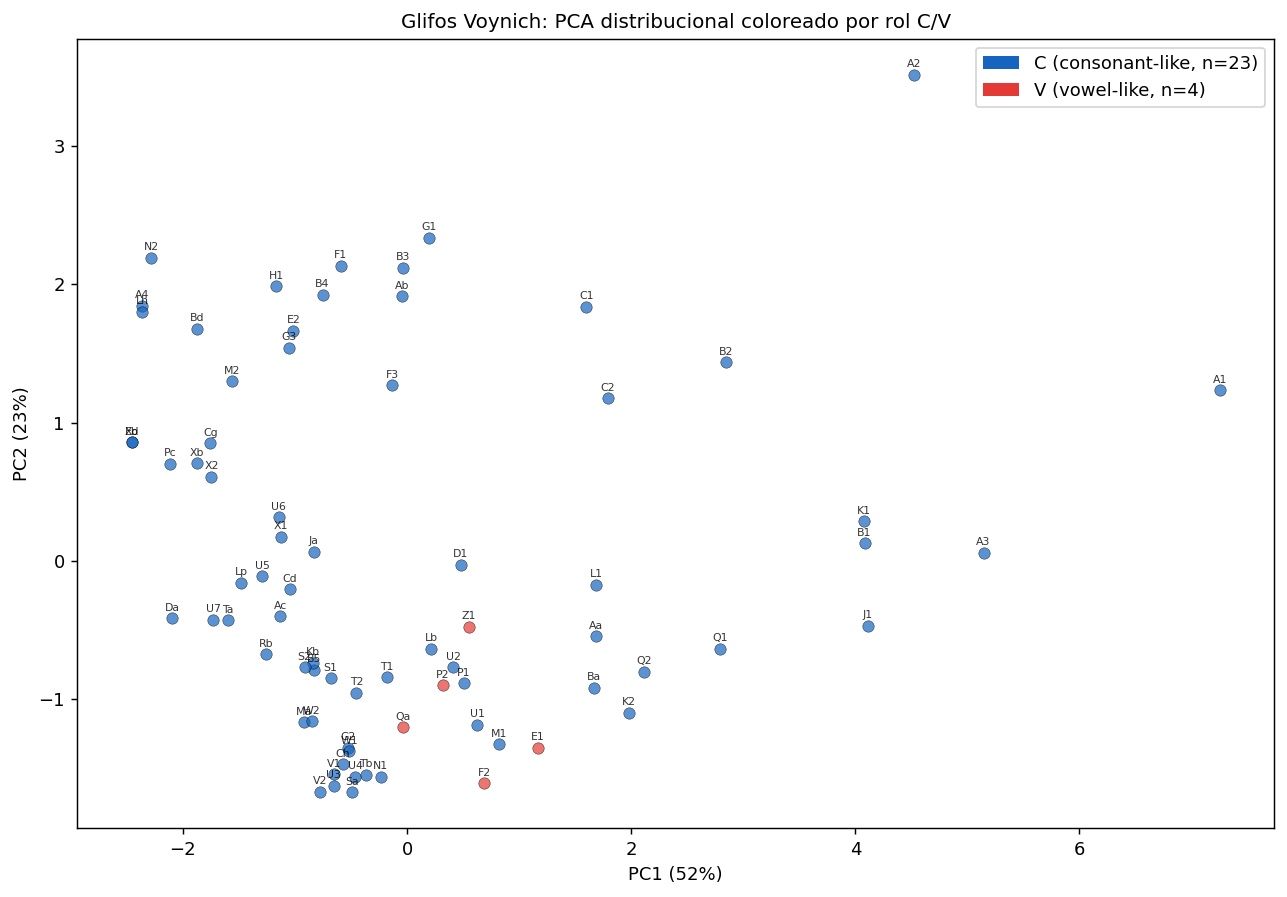

Guardado: aux_docs/compositional_glyphs_pca.png


In [16]:
# ── Cell 7: Glyph analysis + distributional vectors ──────────

# Glyph-level distributional vectors (7-dim, same pattern as syllabic)
def compute_glyph_distributional_vectors(palabras, VOCAB):
    """Compute 7-dim distributional vector per glyph."""
    gf = Counter(g for p in palabras for g in p)
    pos_counts = defaultdict(lambda: [0, 0, 0])  # inicio, medio, final
    left_ctx = defaultdict(set)
    right_ctx = defaultdict(set)

    for word in palabras:
        n = len(word)
        for i, g in enumerate(word):
            if n == 1:
                pos_counts[g][0] += 1
                pos_counts[g][2] += 1
            elif i == 0:
                pos_counts[g][0] += 1
            elif i == n - 1:
                pos_counts[g][2] += 1
            else:
                pos_counts[g][1] += 1
            if i > 0:
                left_ctx[g].add(word[i-1])
            if i < n - 1:
                right_ctx[g].add(word[i+1])

    total = sum(gf.values())
    vectors = {}
    for g in VOCAB:
        if gf[g] < 3:
            continue
        freq_norm = gf[g] / total
        pc = pos_counts[g]
        s = sum(pc) or 1
        pct_ini = pc[0] / s
        pct_mid = pc[1] / s
        pct_fin = pc[2] / s
        n_left = len(left_ctx[g])
        n_right = len(right_ctx[g])
        h_fwd = math.log2(n_right + 1)
        vectors[g] = np.array([freq_norm, pct_ini, pct_mid, pct_fin,
                                h_fwd, n_left, n_right], dtype=float)
    return vectors


vecs_glyph = compute_glyph_distributional_vectors(palabras, VOCAB)
print(f'Glyphs with distributional vector: {len(vecs_glyph)}')

# PCA 2D colored by C/V role
glyphs_for_pca = [g for g in vecs_glyph if glyph_role.get(g, '?') != '?']
if len(glyphs_for_pca) > 5:
    mat = np.array([vecs_glyph[g] for g in glyphs_for_pca])
    mat_norm = (mat - mat.mean(0)) / (mat.std(0) + 1e-8)
    pca = PCA(n_components=2)
    coords = pca.fit_transform(mat_norm)

    fig, ax = plt.subplots(figsize=(10, 7))
    for i, g in enumerate(glyphs_for_pca):
        role = glyph_role[g]
        color = ROLE_COLORS.get(role, '#9E9E9E')
        ax.scatter(coords[i, 0], coords[i, 1], c=color, s=40, alpha=0.7, edgecolors='k', linewidths=0.3)
        ax.annotate(g, (coords[i, 0], coords[i, 1]), fontsize=6, alpha=0.8,
                    ha='center', va='bottom', textcoords='offset points', xytext=(0, 3))

    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
    ax.set_title('Voynich glyphs: distributional PCA colored by C/V role')

    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor=ROLE_COLORS['C'], label=f'C (consonant-like, n={n_c})'),
                       Patch(facecolor=ROLE_COLORS['V'], label=f'V (vowel-like, n={n_v})')]
    ax.legend(handles=legend_elements, loc='upper right')

    plt.tight_layout()
    plt.savefig('images/composicional_glifos_pca.png', bbox_inches='tight')
    plt.show()
    print('Saved: images/composicional_glifos_pca.png')

## Frequency-based initialisation

Unlike the syllabic notebook (which uses the Hungarian algorithm on distributional vectors), here the initialisation is by **frequency within each C/V class**: the most frequent C-class glyph maps to the most frequent C character, etc.

The mapping is many-to-one: as there are ~166 glyphs and ~30 characters, several glyphs map to the same character. The cyclic assignment `glyph_i → char_(i % n_chars)` guarantees coverage.

In [17]:
# ── Cell 9: Frequency-based initialization ──────────────────────────

init_states = {}
init_scores = {}

for nombre in CHAR_DATA:
    d = CHAR_DATA[nombre]
    mapping_dict = init_frequency_mapping(
        palabras, VOCAB, d['vocab'], d['palabras'],
        glyph_role, d['char_role'])

    state = GlyphMappingState(VOCAB, d['vocab'], glyph_role, d['char_role'])
    state.set_mapping(mapping_dict)

    score, components = score_total_comp(state, palabras, d['lm'],
                                         glyph_role, d['char_role'])
    init_states[nombre] = state
    init_scores[nombre] = {'total': score, **components}
    print(f'{nombre}: score_init={score:.4f} (LM={components["lm"]:.4f}, pos={components["pos"]:.2%})')

# Table baseline
rows = []
for nombre in sorted(init_scores, key=lambda n: init_scores[n]['total'], reverse=True):
    s = init_scores[nombre]
    rows.append({'Language': nombre, 'Total score': f'{s["total"]:.4f}',
                 'LM score': f'{s["lm"]:.4f}', 'Pos. score': f'{s["pos"]:.2%}'})
print()
print('Baseline (frequency-based initialization):')
print(pd.DataFrame(rows).to_string(index=False))

Turkish: score_init=-57.2532 (LM=-28.8599, pos=93.33%)
Finnish: score_init=-107.6805 (LM=-54.0902, pos=100.00%)
Hebreo: score_init=-74.0555 (LM=-37.2777, pos=100.00%)
Árabe: score_init=-65.3060 (LM=-32.9030, pos=100.00%)
Latin: score_init=-97.1852 (LM=-48.8426, pos=100.00%)
Arameo: score_init=-79.2044 (LM=-39.8522, pos=100.00%)

Baseline (initialisation por frequency):
 Lengua Score total Score LM Score pos
Turkish    -57.2532 -28.8599    93.33%
  Árabe    -65.3060 -32.9030   100.00%
 Hebreo    -74.0555 -37.2777   100.00%
 Arameo    -79.2044 -39.8522   100.00%
  Latin    -97.1852 -48.8426   100.00%
Finnish   -107.6805 -54.0902   100.00%


## Compositional EM + MCMC

### EM
At each iteration, random changes are proposed (reassign a glyph to another character), accepting only those that improve the score. Stops by patience.

### MCMC
Metropolis-Hastings with adaptive simulated annealing:
- **Proposal**: change the mapping of a random glyph to a random character (respecting C/V constraints)
- **Acceptance**: Metropolis with decreasing temperature
- **Multi-chain**: 4 independent chains for convergence diagnostics (R-hat)

EM composicional:   0%|          | 0/6 [00:00<?, ?it/s]


--- Turkish ---
    iter 1: score=-50.3058 *
    iter 2: score=-47.1834 *
    iter 3: score=-45.9977 *
    iter 4: score=-45.6219 *
    iter 5: score=-43.9603 *
    iter 6: score=-43.5820 *
    iter 7: score=-43.4788 *
    iter 8: score=-43.3056 *
    iter 9: score=-43.0484 *
    iter 10: score=-43.0027 *
    iter 11: score=-42.8432 *
    iter 12: score=-42.7091 *
    iter 13: score=-41.9576 *
    iter 14: score=-41.4503 *
    iter 15: score=-41.2625 *
    iter 16: score=-41.2219 *
    iter 17: score=-41.1473 *
    iter 18: score=-41.1473
    iter 19: score=-41.1438 *
    iter 20: score=-39.8454 *
    iter 21: score=-39.5465 *
    iter 22: score=-39.4321 *
    iter 23: score=-39.4235 *
    iter 24: score=-39.4217 *
    iter 25: score=-39.4065 *
    iter 26: score=-39.4042 *
    iter 27: score=-38.8554 *
    iter 28: score=-38.8554
    iter 29: score=-38.7900 *
    iter 30: score=-38.7165 *
    iter 31: score=-38.7152 *
    iter 32: score=-38.6009 *
    iter 33: score=-38.3597 *
    it

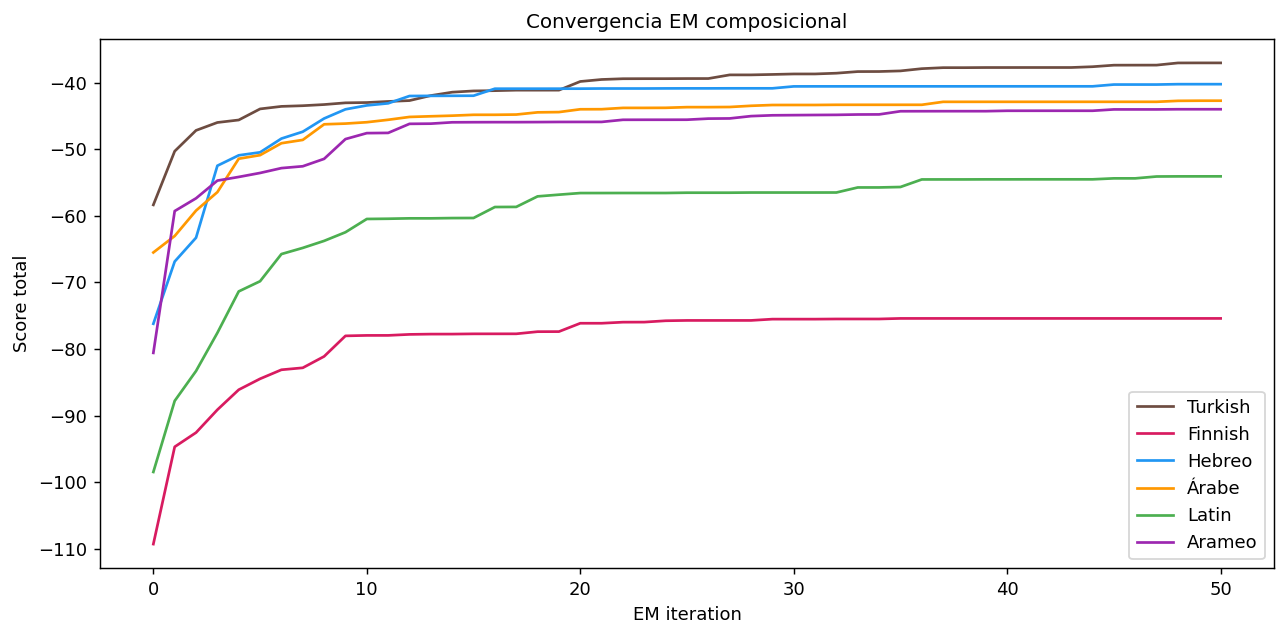

Guardado: aux_docs/compositional_em_convergence.png


In [18]:
# ── Cell 11: Compositional EM ────────────────────────────────────────

EM_COMP = {}
for nombre in tqdm(CHAR_DATA, desc='Compositional EM'):
    print(f'\n--- {nombre} ---')
    state, scores = em_glyph_decipher(
        palabras, CHAR_DATA[nombre]['lm'],
        glyph_role, CHAR_DATA[nombre]['char_role'],
        init_states[nombre], n_iter=50, patience=10,
        sample_size=3000, changes_per_iter=200)
    EM_COMP[nombre] = {'state': state, 'scores': scores}

# EM score table
print('\n' + '='*60)
print('Compositional EM results:')
rows = []
for nombre in sorted(EM_COMP, key=lambda n: EM_COMP[n]['scores'][-1], reverse=True):
    s = EM_COMP[nombre]['scores']
    rows.append({'Language': nombre, 'Final score': f'{s[-1]:.4f}',
                 'Initial score': f'{s[0]:.4f}', 'Improvement': f'{s[-1]-s[0]:.4f}',
                 'Iterations': len(s)-1})
print(pd.DataFrame(rows).to_string(index=False))

# EM convergence
fig, ax = plt.subplots(figsize=(10, 5))
for nombre in EM_COMP:
    ax.plot(EM_COMP[nombre]['scores'], label=nombre, color=LANG_COLORS.get(nombre, 'gray'), linewidth=1.5)
ax.set_xlabel('EM iteration')
ax.set_ylabel('Total score')
ax.set_title('Compositional EM convergence')
ax.legend()
plt.tight_layout()
plt.savefig('images/composicional_em_convergencia.png', bbox_inches='tight')
plt.show()
print('Saved: images/composicional_em_convergencia.png')

In [19]:
# ── Cell 12: Multi-chain MCMC (top-2 languages from EM) ────────────────

# Only top-2 due to computational cost
top2 = sorted(EM_COMP, key=lambda n: EM_COMP[n]['scores'][-1], reverse=True)[:2]
print(f'Top-2 languages for MCMC: {top2}')

MCMC_COMP = {}
for nombre in top2:
    print(f'\n{"="*60}')
    print(f'MCMC for {nombre}')
    print(f'{"="*60}')
    result = mcmc_glyph_multi_chain(
        EM_COMP[nombre]['state'], palabras, CHAR_DATA[nombre]['lm'],
        glyph_role, CHAR_DATA[nombre]['char_role'],
        n_chains=4, n_iter=15000, burn_in=3000, thin=5,
        adaptive=True, target_accept=0.35,
        sample_size=3000)
    MCMC_COMP[nombre] = result
    print(f'  Best score: {result["best_score"]:.4f}')
    for i, ch in enumerate(result['chains']):
        print(f'    Chain {i+1}: best={ch["best_score"]:.4f}, accept={ch["accept_rate"]:.1%}')

Top-2 languages para MCMC: ['Turkish', 'Hebreo']

MCMC para Turkish
  Chain 1/4 (seed=42)
    Adaptive T: median|delta|=0.0155 -> T_start=0.014719, T_end=0.00014719
    MCMC iter 3000: score=-36.6374, best=-36.5880, T=0.005861, accept=75.5%
    MCMC iter 6000: score=-36.5572, best=-36.5383, T=0.002333, accept=72.7%
    MCMC iter 9000: score=-36.4580, best=-36.4526, T=0.000929, accept=69.7%
    MCMC iter 12000: score=-36.0415, best=-36.0415, T=0.000370, accept=67.4%
    MCMC iter 15000: score=-35.2557, best=-35.2557, T=0.000147, accept=65.8%
  Chain 2/4 (seed=137)
    Adaptive T: median|delta|=0.0414 -> T_start=0.039473, T_end=0.00039473
    MCMC iter 3000: score=-37.1383, best=-37.0812, T=0.015718, accept=80.5%
    MCMC iter 6000: score=-36.7622, best=-36.7478, T=0.006257, accept=77.6%
    MCMC iter 9000: score=-35.7740, best=-35.7740, T=0.002491, accept=75.0%
    MCMC iter 12000: score=-35.7129, best=-35.7129, T=0.000992, accept=72.7%
    MCMC iter 15000: score=-35.6924, best=-35.6923

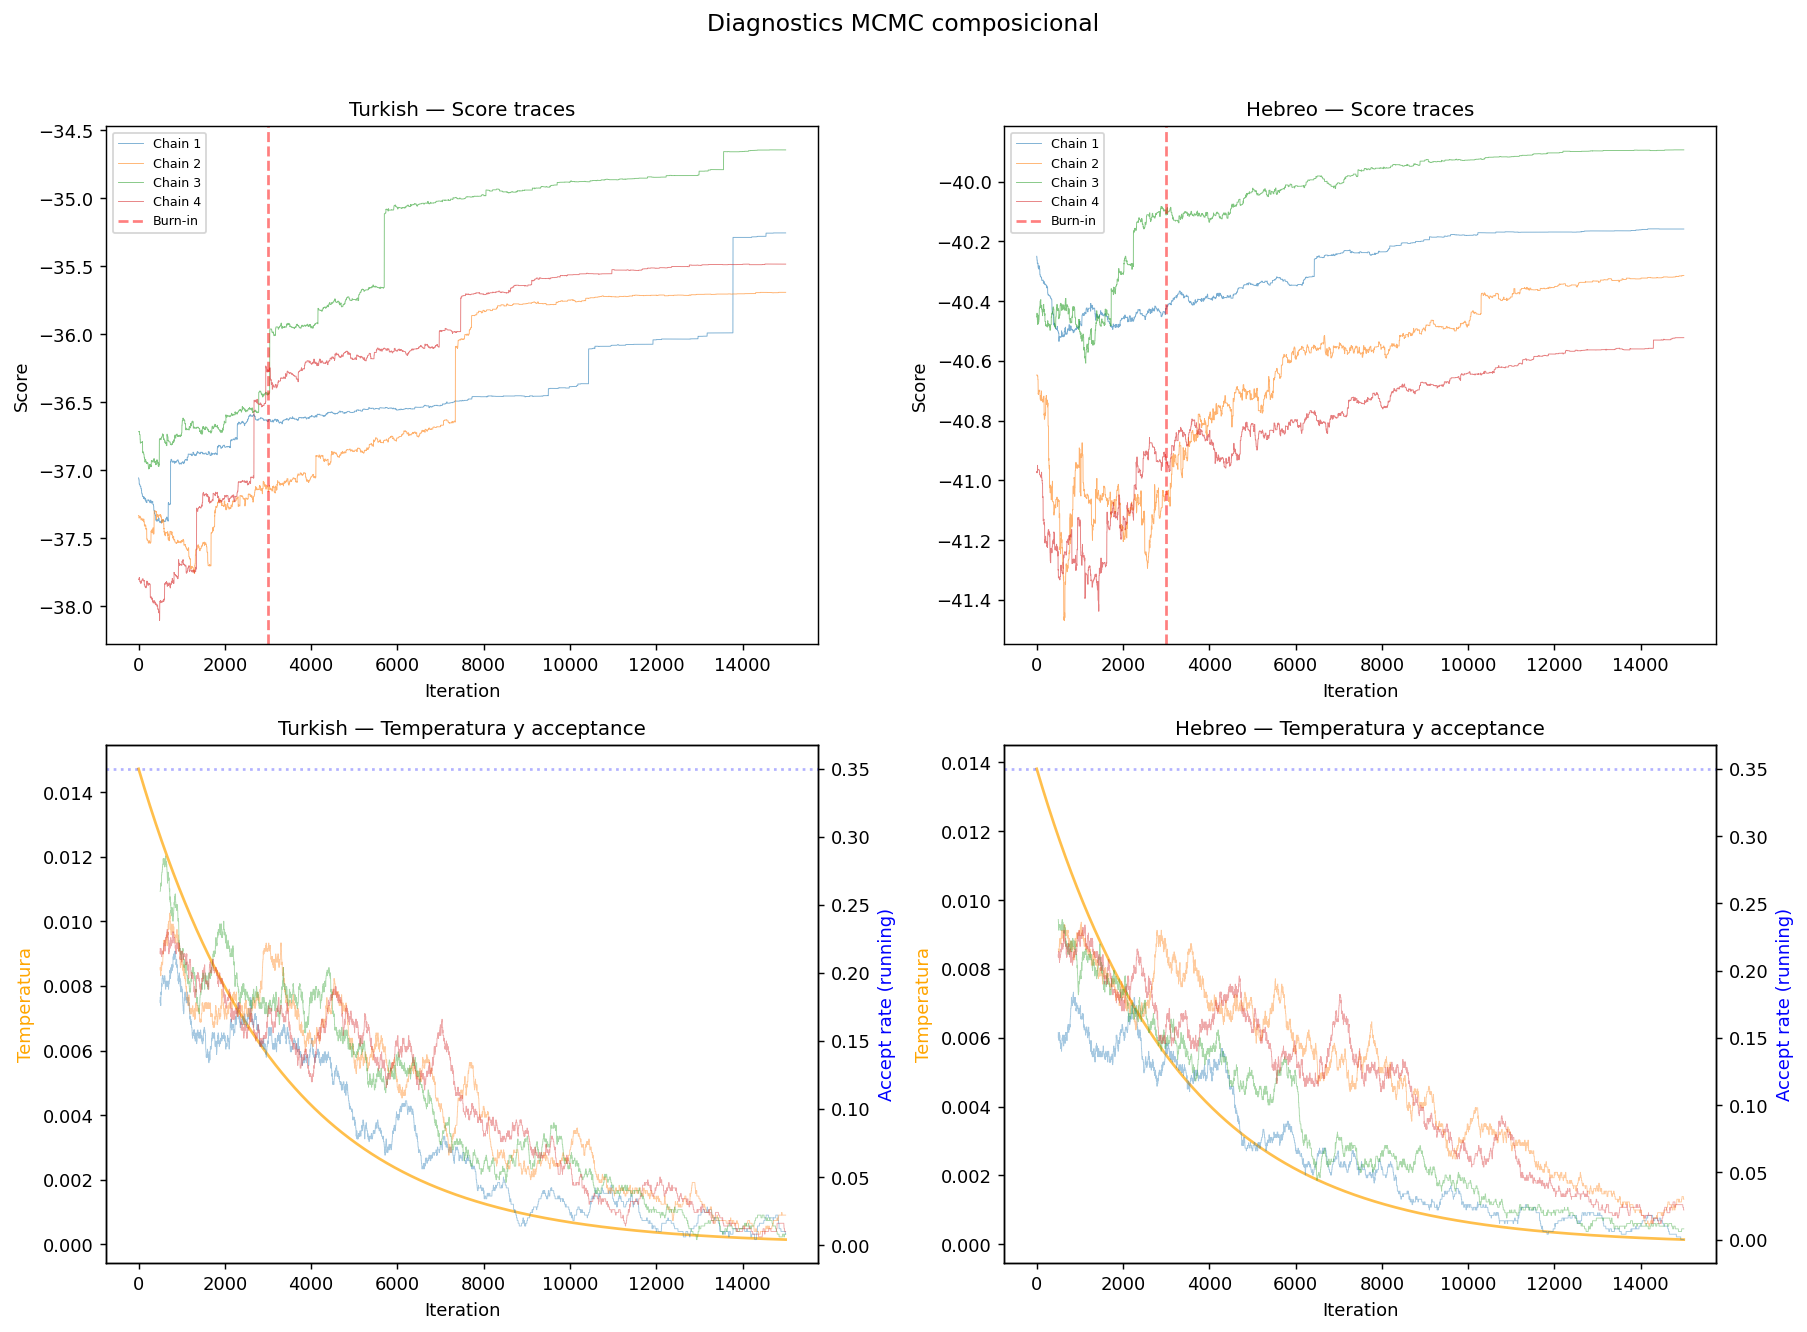

Guardado: aux_docs/compositional_mcmc_diagnostics.png


In [20]:
# ── Cell 13: MCMC diagnostics ───────────────────────────────────────

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for lang_idx, nombre in enumerate(MCMC_COMP):
    result = MCMC_COMP[nombre]
    chains = result['chains']

    # Score traces
    ax = axes[0, lang_idx]
    for i, ch in enumerate(chains):
        scores = ch['chain_scores']
        ax.plot(scores, alpha=0.6, linewidth=0.5, label=f'Chain {i+1}')
    ax.axvline(result['burn_in'], color='red', linestyle='--', alpha=0.5, label='Burn-in')
    ax.set_title(f'{nombre} — Score traces')
    ax.set_xlabel('Iteration')
    ax.set_ylabel('Score')
    ax.legend(fontsize=7)

    # Temperature + acceptance
    ax = axes[1, lang_idx]
    temps = chains[0]['temperatures']
    ax.plot(temps, color='orange', alpha=0.7, label='Temperature')
    ax.set_ylabel('Temperature', color='orange')
    ax.set_xlabel('Iteration')
    ax.set_title(f'{nombre} — Temperature and acceptance')

    ax2 = ax.twinx()
    for i, ch in enumerate(chains):
        # Running acceptance rate
        scores = ch['chain_scores']
        n = len(scores)
        window = 500
        if n > window:
            running_accept = []
            for j in range(window, n):
                changes = sum(1 for k in range(j-window, j) if scores[k] != scores[k-1]) if j > 0 else 0
                running_accept.append(changes / window)
            ax2.plot(range(window, n), running_accept, alpha=0.4, linewidth=0.5)
    ax2.set_ylabel('Accept rate (running)', color='blue')
    ax2.axhline(0.35, color='blue', linestyle=':', alpha=0.3)

plt.suptitle('Compositional MCMC diagnostics', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('images/composicional_mcmc_diagnosticos.png', bbox_inches='tight')
plt.show()
print('Saved: images/composicional_mcmc_diagnosticos.png')


Turkish:
  Muestras post-burn-in: 9604
  Glifos mapeados: 166
  Confianza media: 24.9%, mediana: 10.9%
  R-hat < 1.1: 94/164 (57%)
  R-hat: mean=1.192, median=1.056, max=3.130

Hebreo:
  Muestras post-burn-in: 9604
  Glifos mapeados: 166
  Confianza media: 27.8%, mediana: 11.5%
  R-hat < 1.1: 98/165 (59%)
  R-hat: mean=1.176, median=1.040, max=4.875


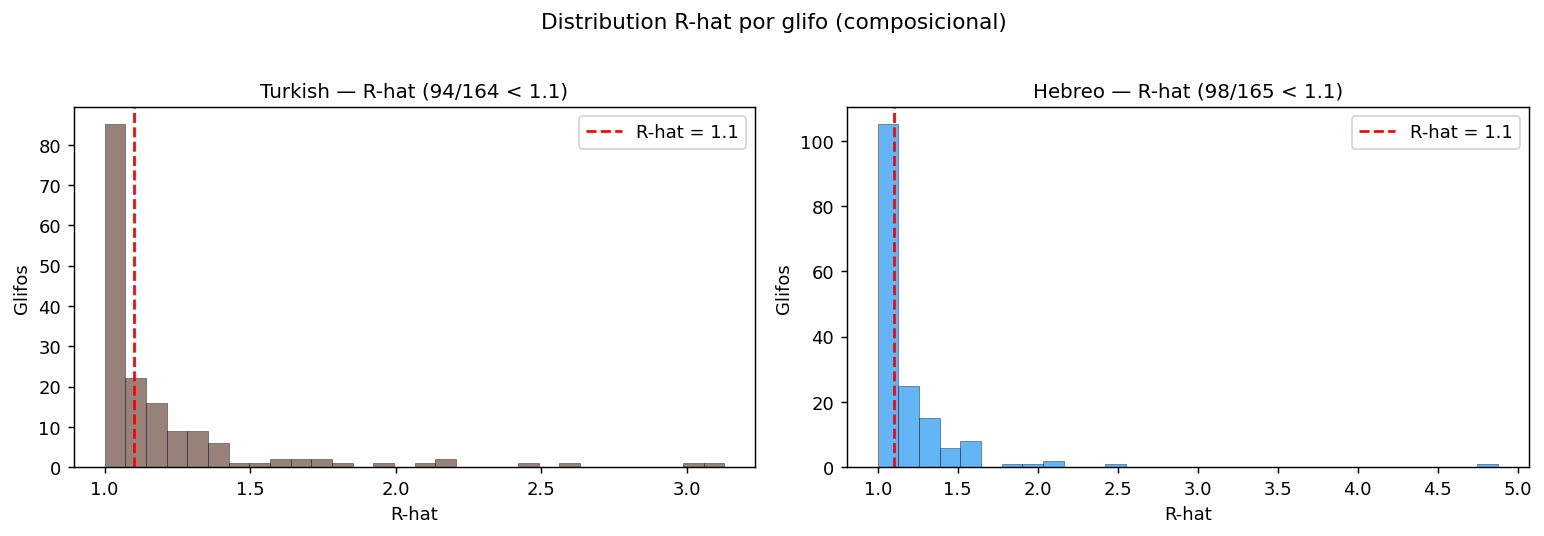

Guardado: aux_docs/compositional_rhat.png


In [21]:
# ── Cell 14: Posterior + R-hat ───────────────────────────────────────

POSTERIOR_COMP = {}
RHAT_COMP = {}

for nombre in MCMC_COMP:
    posterior, rhat, n_samples = posterior_glyph_multi_chain(
        MCMC_COMP[nombre], burn_in=3000)
    POSTERIOR_COMP[nombre] = posterior
    RHAT_COMP[nombre] = rhat

    # Per-glyph confidence
    confidences = []
    for g, probs in posterior.items():
        if probs:
            confidences.append(max(probs.values()))
    mean_conf = np.mean(confidences) if confidences else 0
    median_conf = np.median(confidences) if confidences else 0

    # R-hat stats
    rhat_vals = [v for v in rhat.values() if not np.isnan(v) and v != float('inf')]
    n_converged = sum(1 for v in rhat_vals if v < 1.1)

    print(f'\n{nombre}:')
    print(f'  Post-burn-in samples: {n_samples}')
    print(f'  Mapped glyphs: {len(posterior)}')
    print(f'  Mean confidence: {mean_conf:.1%}, median: {median_conf:.1%}')
    print(f'  R-hat < 1.1: {n_converged}/{len(rhat_vals)} ({n_converged/max(len(rhat_vals),1):.0%})')
    if rhat_vals:
        print(f'  R-hat: mean={np.mean(rhat_vals):.3f}, median={np.median(rhat_vals):.3f}, '
              f'max={np.max(rhat_vals):.3f}')

# R-hat histogram
n_langs = len(RHAT_COMP)
fig, axes = plt.subplots(1, n_langs, figsize=(6*n_langs, 4))
if n_langs == 1:
    axes = [axes]
for ax, nombre in zip(axes, RHAT_COMP):
    rhat_vals = [v for v in RHAT_COMP[nombre].values()
                 if not np.isnan(v) and v != float('inf')]
    if rhat_vals:
        ax.hist(rhat_vals, bins=30, color=LANG_COLORS.get(nombre, 'gray'),
                alpha=0.7, edgecolor='black', linewidth=0.3)
        ax.axvline(1.1, color='red', linestyle='--', label='R-hat = 1.1')
        n_conv = sum(1 for v in rhat_vals if v < 1.1)
        ax.set_title(f'{nombre} — R-hat ({n_conv}/{len(rhat_vals)} < 1.1)')
    ax.set_xlabel('R-hat')
    ax.set_ylabel('Glyphs')
    ax.legend()

plt.suptitle('Per-glyph R-hat distribution (compositional)', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('images/composicional_rhat.png', bbox_inches='tight')
plt.show()
print('Saved: images/composicional_rhat.png')

## Evaluation and reconstruction

Final ranking of candidate languages with detailed metrics. Comparison with the syllabic ranking from the Bayesian notebook.

In [22]:
# ── Cell 16: Final ranking ───────────────────────────────────────────

rows = []
for nombre in CHAR_DATA:
    # Use MCMC best state if available, else EM
    if nombre in MCMC_COMP:
        state = MCMC_COMP[nombre]['best_state']
    else:
        state = EM_COMP[nombre]['state']

    score, components = score_total_comp(state, palabras, CHAR_DATA[nombre]['lm'],
                                         glyph_role, CHAR_DATA[nombre]['char_role'])
    # Mapped PPX
    mapped_corpus = state.apply_corpus(palabras)
    ppx_mapped = CHAR_DATA[nombre]['lm'].perplexity(mapped_corpus)
    ppx_native = CHAR_DATA[nombre]['ppx_native']

    rows.append({
        'Language': nombre,
        'Total score': score,
        'LM score': components['lm'],
        'Pos. score': components['pos'],
        'Mapped PPX': ppx_mapped,
        'Native PPX': ppx_native,
        'PPX ratio': ppx_mapped / ppx_native if ppx_native > 0 else float('inf'),
    })

df_ranking = pd.DataFrame(rows).sort_values('Total score', ascending=False).reset_index(drop=True)
df_ranking.index += 1
df_ranking.index.name = '#'

print('Compositional ranking (glyph → character):')
print(df_ranking.to_string())

# ── Comparison with syllabic ranking ──
syl_results_path = 'bayesiano_silabico_resultados.json'
if os.path.exists(syl_results_path):
    with open(syl_results_path) as f:
        syl_results = json.load(f)
    print('\n' + '='*60)
    print('Comparison with syllabic ranking:')
    syl_ranking = syl_results.get('ranking', [])
    if syl_ranking:
        print(f'  Syllabic: {" > ".join(r["language"] for r in syl_ranking)}')
        print(f'  Compositional: {" > ".join(df_ranking["Language"].tolist())}')

        # Concordancia
        syl_order = [r['language'] for r in syl_ranking]
        comp_order = df_ranking['Language'].tolist()
        match_top1 = syl_order[0] == comp_order[0] if syl_order and comp_order else False
        match_top2 = set(syl_order[:2]) == set(comp_order[:2]) if len(syl_order) >= 2 and len(comp_order) >= 2 else False
        print(f'  Top-1 match: {match_top1}')
        print(f'  Top-2 match: {match_top2}')
else:
    print('\n(bayesiano_silabico_resultados.json not found for comparison)')

Ranking compositional (glyph → character):
    Lengua  Score total   Score LM  Score pos  PPX mapeada  PPX nativa  Ratio PPX
#                                                                                
1  Turkish   -34.722736 -17.594701   0.933333    10.688142    7.929787   1.347847
2   Hebreo   -39.705394 -20.102697   1.000000    15.146646    7.306710   2.072978
3    Árabe   -42.321293 -21.410646   1.000000    17.901432    7.302020   2.451573
4   Arameo   -43.580593 -22.040297   1.000000    19.426267    7.382287   2.631470
5    Latin   -53.440009 -26.970005   1.000000    38.282183    5.635850   6.792620
6  Finnish   -74.439260 -37.469630   1.000000   158.312677    7.394040  21.410849

Comparison con ranking syllabic:
  Syllabic: Hebreo > Arameo > Árabe > Finnish > Latin > Turkish
  Compositional: Turkish > Hebreo > Árabe > Arameo > Latin > Finnish
  Top-1 coincide: False
  Top-2 coincide: False


In [23]:
# ── Cell 17: Text reconstruction ────────────────────────────────

best_lang = df_ranking.iloc[0]['Language']
print(f'Reconstruction with top-1 language: {best_lang}')
print()

if best_lang in MCMC_COMP:
    best_state = MCMC_COMP[best_lang]['best_state']
    posterior = POSTERIOR_COMP[best_lang]
else:
    best_state = EM_COMP[best_lang]['state']
    posterior = {}

# First 50 words
print(f'{"#":>3}  {"Voynich":<30}  {"Mapped":<30}  {"Confidence"}')
print('-' * 85)
for idx, word in enumerate(palabras[:50]):
    word_str = '-'.join(word)
    mapped = best_state.apply_word(word)
    mapped_str = ''.join(mapped)

    # Per-glyph confidence
    confs = []
    for g in word:
        probs = posterior.get(g, {})
        if probs:
            confs.append(max(probs.values()))
        else:
            confs.append(0.0)
    mean_conf = np.mean(confs) if confs else 0
    conf_bar = '█' * int(mean_conf * 10) + '░' * (10 - int(mean_conf * 10))

    print(f'{idx+1:>3}  {word_str:<30}  {mapped_str:<30}  {mean_conf:.0%} {conf_bar}')

Reconstruction con language top-1: Turkish

  #  Voynich                         Mapeada                         Confianza
-------------------------------------------------------------------------------------
  1  P2-A3-K1-A2-C2                  niden                           84% ████████░░
  2  A2-Q1-A3-B2                     enin                            100% ██████████
  3  A3-C1                           in                              100% ██████████
  4  Aa-Q2-A3-G1                     enin                            88% ████████░░
  5  L1-A1-B2                        den                             97% █████████░
  6  L1-A1-C1-A2                     dene                            98% █████████░
  7  U5-C2-J1-C2                     anin                            58% █████░░░░░
  8  A2                              e                               100% ██████████
  9  Q1-A1-C1                        nen                             100% ██████████
 10  L1-A1-B2-B1-A2            

Top 30 mappings more confiables (Turkish):
Glifo Character  Confianza Rol glifo Rol char  Freq glifo
   A1         e   1.000000         C        C       25106
   A2         e   1.000000         C        C       17464
   A3         i   1.000000         C        C       14545
   B2         n   1.000000         C        C       10668
   C1         n   1.000000         C        C        6770
   Q1         n   1.000000         C        C        9935
   G1         n   1.000000         C        C        4162
   K2         i   1.000000         C        C        4442
   Q2         n   1.000000         C        C        6113
   D1         d   1.000000         C        C        5425
   B3         n   1.000000         C        C        1065
   F3         n   1.000000         C        C         623
   G3         n   0.956164         C        C         176
   P1         n   0.903374         C        C        1442
   L1         d   0.900875         C        C        4174
   M1         i   0.789983   

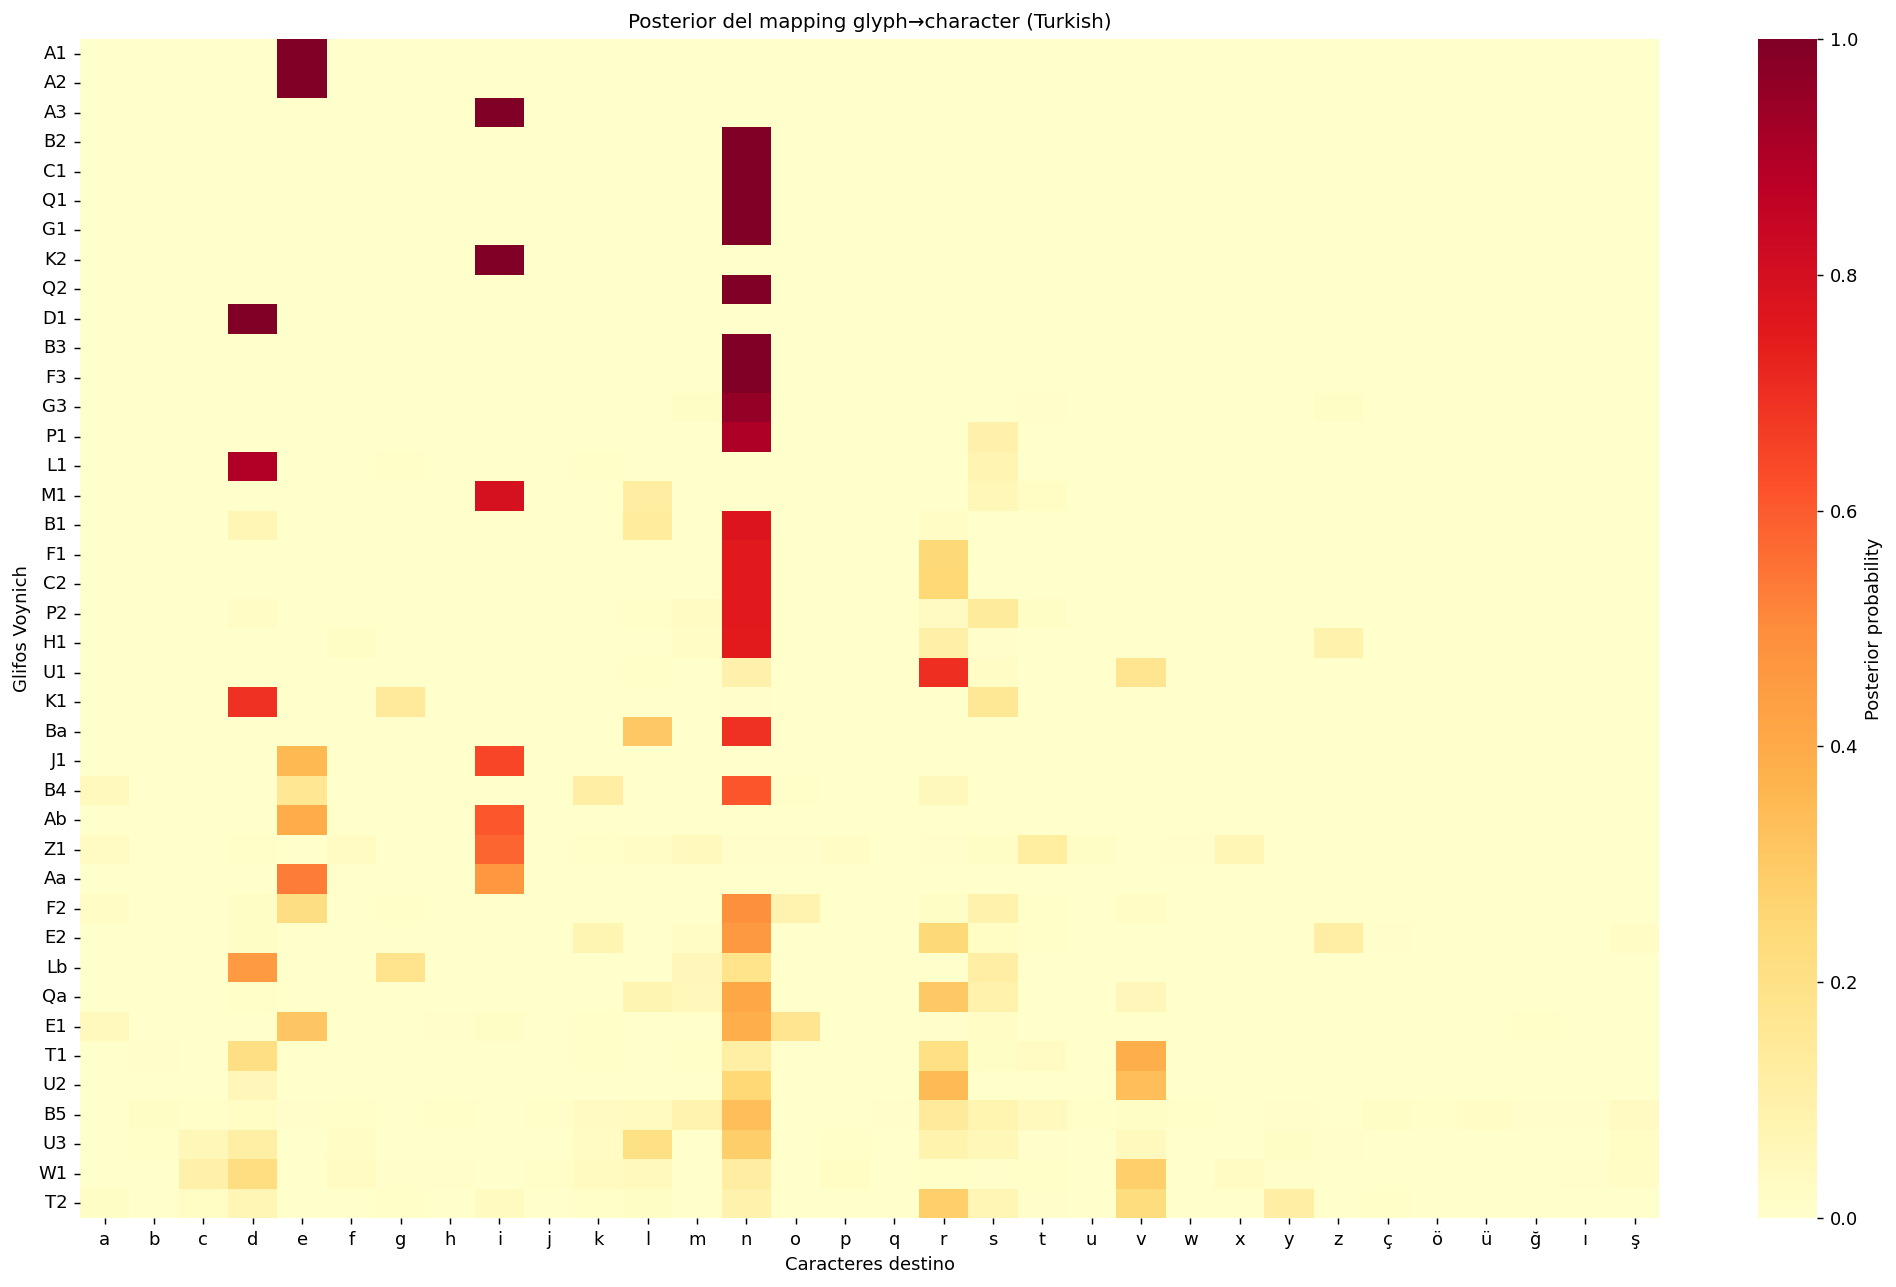

Guardado: aux_docs/compositional_mapping_heatmap.png


In [24]:
# ── Cell 18: Mapping table + heatmap ─────────────────────────────

if best_lang in POSTERIOR_COMP:
    posterior = POSTERIOR_COMP[best_lang]

    # Top-30 most confident mappings
    mapping_rows = []
    for g, probs in posterior.items():
        if not probs:
            continue
        best_char = max(probs, key=probs.get)
        conf = probs[best_char]
        mapping_rows.append({
            'Glyph': g, 'Character': best_char, 'Confidence': conf,
            'Glyph role': glyph_role.get(g, '?'),
            'Char role': CHAR_DATA[best_lang]['char_role'].get(best_char, '?'),
            'Glyph freq': glyph_freq.get(g, 0),
        })

    df_map = pd.DataFrame(mapping_rows).sort_values('Confidence', ascending=False).reset_index(drop=True)
    print(f'Top 30 most confident mappings ({best_lang}):')
    print(df_map.head(30).to_string(index=False))

    # C/V consistency
    n_consistent = sum(1 for _, r in df_map.iterrows()
                       if r['Glyph role'] == r['Char role'] and r['Glyph role'] != '?')
    n_total_typed = sum(1 for _, r in df_map.iterrows() if r['Glyph role'] != '?')
    print(f'\nC/V consistency: {n_consistent}/{n_total_typed} ({n_consistent/max(n_total_typed,1):.0%})')

    # Heatmap: glyphs (filas) × chars (columnas)
    top_glyphs = df_map.head(40)['Glyph'].tolist()
    target_chars = sorted(CHAR_DATA[best_lang]['vocab'])

    heat_data = np.zeros((len(top_glyphs), len(target_chars)))
    for i, g in enumerate(top_glyphs):
        probs = posterior.get(g, {})
        for j, c in enumerate(target_chars):
            heat_data[i, j] = probs.get(c, 0)

    fig, ax = plt.subplots(figsize=(max(12, len(target_chars)*0.5), max(8, len(top_glyphs)*0.25)))
    sns.heatmap(heat_data, xticklabels=target_chars, yticklabels=top_glyphs,
                cmap='YlOrRd', ax=ax, vmin=0, vmax=1,
                cbar_kws={'label': 'Posterior probability'})
    ax.set_xlabel('Target characters')
    ax.set_ylabel('Voynich glyphs')
    ax.set_title(f'Glyph→character mapping posterior ({best_lang})')
    plt.tight_layout()
    plt.savefig('images/composicional_mapping_heatmap.png', bbox_inches='tight')
    plt.show()
    print('Saved: images/composicional_mapping_heatmap.png')
else:
    print('No MCMC posterior available for heatmap')

In [25]:
# ── Cell 19: Export JSON ─────────────────────────────────────────────

# Ranking data
ranking_data = []
for _, row in df_ranking.iterrows():
    ranking_data.append({
        'nombre': row['Language'],
        'score_total': float(row['Total score']),
        'score_lm': float(row['LM score']),
        'score_pos': float(row['Pos. score']),
        'ppx_mapped': float(row['Mapped PPX']),
        'ppx_native': float(row['Native PPX']),
        'ratio_ppx': float(row['PPX ratio']),
    })

# Mapping data
mapping_data = {}
for nombre in MCMC_COMP:
    state = MCMC_COMP[nombre]['best_state']
    mapping_data[nombre] = {g: c for g, c in state.mapping.items()}

# Posterior data (top-5 per glyph)
posterior_data = {}
for nombre in POSTERIOR_COMP:
    posterior_data[nombre] = {}
    for g, probs in POSTERIOR_COMP[nombre].items():
        top5 = sorted(probs.items(), key=lambda x: x[1], reverse=True)[:5]
        posterior_data[nombre][g] = {c: round(p, 4) for c, p in top5}

# MCMC diagnostics
mcmc_diag = {}
for nombre in MCMC_COMP:
    rhat_vals = [v for v in RHAT_COMP[nombre].values()
                 if not np.isnan(v) and v != float('inf')]
    confs = []
    for g, probs in POSTERIOR_COMP[nombre].items():
        if probs:
            confs.append(max(probs.values()))
    mcmc_diag[nombre] = {
        'n_chains': MCMC_COMP[nombre]['n_chains'],
        'n_iter': MCMC_COMP[nombre]['n_iter'],
        'accept_rates': [ch['accept_rate'] for ch in MCMC_COMP[nombre]['chains']],
        'rhat_mean': float(np.mean(rhat_vals)) if rhat_vals else None,
        'rhat_median': float(np.median(rhat_vals)) if rhat_vals else None,
        'rhat_pct_below_1_1': float(sum(1 for v in rhat_vals if v < 1.1) / max(len(rhat_vals), 1)) if rhat_vals else None,
        'confidence_mean': float(np.mean(confs)) if confs else None,
        'confidence_median': float(np.median(confs)) if confs else None,
    }

# Comparison with syllabic
comparison = {}
if os.path.exists('bayesiano_silabico_resultados.json'):
    with open('bayesiano_silabico_resultados.json') as f:
        syl_results = json.load(f)
    syl_ranking = syl_results.get('ranking', [])
    if syl_ranking:
        syl_order = [r['language'] for r in syl_ranking]
        comp_order = [r['nombre'] for r in ranking_data]
        comparison = {
            'syllabic_ranking': syl_order,
            'compositional_ranking': comp_order,
            'top1_match': syl_order[0] == comp_order[0] if syl_order and comp_order else False,
            'top2_match': set(syl_order[:2]) == set(comp_order[:2]) if len(syl_order) >= 2 and len(comp_order) >= 2 else False,
        }

results = {
    'metadata': {
        'model': 'compositional_silpart_aware',
        'n_glyphs': len(VOCAB),
        'n_words': N_VOYNICH,
        'lm_type': 'trigram_char_witten_bell',
        'mapping_type': 'many_to_one',
    },
    'glyph_classification': {
        'n_consonant': n_c, 'n_vowel': n_v, 'n_unknown': n_q,
        'ratio_v_cv': n_v / (n_c + n_v) if (n_c + n_v) > 0 else 0,
    },
    'ranking': ranking_data,
    'mapping': mapping_data,
    'posterior': posterior_data,
    'mcmc_diagnostics': mcmc_diag,
    'comparison_syllabic': comparison,
}

with open('composicional_resultados.json', 'w', encoding='utf-8') as f:
    json.dump(results, f, ensure_ascii=False, indent=2, default=str)

print(f'Saved: composicional_resultados.json')
print(f'  Ranking: {" > ".join(r["nombre"] for r in ranking_data)}')
print(f'  Glyphs: {len(VOCAB)} (C={n_c}, V={n_v}, ?={n_q})')
if comparison:
    print(f'  Syllabic comparison: top-1 {"✓" if comparison["top1_match"] else "✗"}, '
          f'top-2 {"✓" if comparison["top2_match"] else "✗"}')

Guardado: compositional_results.json
  Ranking: Turkish > Hebreo > Árabe > Arameo > Latin > Finnish
  Glifos: 166 (C=23, V=4, ?=91)
  Comparison syllabic: top-1 ✗, top-2 ✗


## Conclusions

### Compositional vs syllabic ranking

- **Does the compositional ranking confirm the syllabic one?** Compare the positions of the 5 candidate languages between both approaches.
- **Does mapping confidence improve?** With ~166 glyphs × ~30 characters (vs ~800! permutations), the search space is drastically smaller, which should produce better MCMC mixing and higher posterior confidence.
- **Are the reconstructions more readable?** The glyph→character mapping produces individual character sequences, more easily interpretable than syllable sequences.

### SilPart compositional model

If the Voynich truly uses compositional encoding (as suggested by the SilPart model with d=0.445), the glyph→character mapping is the most natural representation. The results of this notebook provide independent evidence about the underlying language, complementing the syllabic analysis.

## Limitations

1. **Trigram CharLM is limited**: Does not capture dependencies longer than 3 characters. A neural LM (LSTM/Transformer) could improve scoring, but at greater computational cost.

2. **Glyph C/V classification is heuristic**: Based on the proportion of appearances in syllables classified as nuclear. Ambiguous glyphs (like semivowels or matres lectionis) may be misclassified.

3. **Matres lectionis in Hebrew/Arabic**: Consonants that function as vowel indicators (alef, he, vav, yod in Hebrew; alif, waw, ya in Arabic) blur the C/V distinction, as they are formally consonants but functionally vocalic.

4. **Does not model multi-character glyphs**: Assumes 1-to-1 mapping (one glyph = one character). A glyph could encode 2+ characters (digraph), or a character could be encoded by a sequence of glyphs.

5. **Many-to-one without cardinality constraint**: No limit on how many glyphs can map to the same character, which could produce degenerate solutions.